In [ ]:
# 匯入套件：Flatten 負責把 2D 影像攤平成 1D 向量
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Flatten

## 載入資料

In [ ]:
# 載入 MNIST 手寫數字資料集（第一次執行會自動下載）
# train：60000 張訓練圖，test：10000 張測試圖，每張為 28x28 灰階影像
mnist = keras.datasets.mnist
(train_data, train_label), (test_data, test_label) = mnist.load_data()

In [ ]:
# 檢視資料型態與形狀
print(type(train_data))
print(train_data.shape)    # (60000, 28, 28)
print(type(train_label))
print(train_label.shape)   # (60000,)
print(test_data.shape)     # (10000, 28, 28)
print(test_label.shape)    # (10000,)

<class 'numpy.ndarray'>
(60000, 28, 28)
<class 'numpy.ndarray'>
(60000,)
(10000, 28, 28)
(10000,)


In [ ]:
# 第一張圖的標籤與像素值（每個像素為 0~255 的灰階值）
print(train_label[0])
print(train_data[0])

5
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 

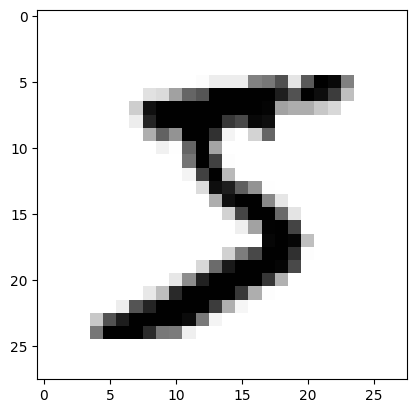

In [ ]:
# 把第一張圖畫出來
import matplotlib.pyplot as plt
plt.imshow(train_data[0], cmap='binary')
plt.show()

In [ ]:
# 資料正規化：把像素值從 0~255 縮放到 0~1，可讓訓練更穩定、收斂更快
train_data = train_data / 255.0
test_data = test_data / 255.0

## 建立與編譯模型

In [ ]:
model = Sequential()
# 輸入層：把 28x28 的影像攤平成 784 維向量
model.add(Flatten(input_shape=(28, 28)))
# 隱藏層：64 個神經元，激活函數 relu
model.add(Dense(64, activation='relu'))
# 輸出層：10 個神經元對應數字 0~9，softmax 讓 10 個輸出加總為 1（機率分布）
model.add(Dense(10, activation='softmax'))
# 標籤是整數 0~9，所以損失函數使用 sparse_categorical_crossentropy
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## 訓練與評估

In [ ]:
# 訓練：10 個 epoch，每批 256 筆
model.fit(train_data, train_label, epochs=10, batch_size=256)

# 用從未訓練過的測試集評估，score[1] 為測試準確率
score = model.evaluate(test_data, test_label)
print(score[1])

Epoch 1/10


  1/235 ━━━━━━━━━━━━━━━━━━━━ 4:37 1s/step - accuracy: 0.1211 - loss: 2.3777

 21/235 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5396 - loss: 1.6875 

 42/235 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6737 - loss: 1.2594

 61/235 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7315 - loss: 1.0380

...

201/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9644 - loss: 0.1203  

247/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9675 - loss: 0.1089

292/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9698 - loss: 0.0990

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9690 - loss: 0.1009


0.968999981880188
